###  **Title: DSC670-T301 Advanced Uses of Generative AI (2271-1)**
####  **Professor:** *Frank Neugebauer*
####  **Date: 01 Oct 2026**
####  **Author:** *Akhil Anand Thazhaniyil Muralidharan*
####  **Description:** Milestone 2 : Fine Tuning a LLM for Telecom Plan Selection and Billing Assistance.

*************

### Refined Problem Statement

Telecom assistants must follow supplied plan and billing facts, respect customer constraints, and avoid invented details. This milestone compares three prompting strategies on the same lightweight language model.

**Research question:** How do zero-shot, one-shot, and chain-of-thought prompts affect groundedness, relevance, clarity, completeness, and safety in telecom assistance responses?

The comparison uses the same five scenarios and deterministic generation settings for all three strategies. No model fine-tuning is required.

### Import Required Libraries


In [27]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Model:", MODEL_NAME)
print("Output directory:", OUTPUT_DIR.resolve())

Model: Qwen/Qwen2.5-0.5B-Instruct
Output directory: /Users/athazh341@apac.comcast.com/Library/CloudStorage/OneDrive-Comcast/AkhilAnandTM/BVU/DSC670/Assignments/Week4/output


### Data Setup

The project does not use proprietary customer or company data. The following catalog is synthetic and exists only to test grounded reasoning. Prices and features are fictional. Keeping the facts inside the notebook makes it possible to verify whether a response used the supplied evidence or invented information.


In [28]:
plan_catalog = pd.DataFrame([
    {"plan": "Connect 200", "monthly_price": 45, "download_mbps": 200, "upload_mbps": 10, "data_allowance": "1.2 TB"},
    {"plan": "Work 500", "monthly_price": 70, "download_mbps": 500, "upload_mbps": 50, "data_allowance": "1.2 TB"},
    {"plan": "Gig 1000", "monthly_price": 95, "download_mbps": 1000, "upload_mbps": 100, "data_allowance": "Unlimited"},
    {"plan": "Family 500", "monthly_price": 85, "download_mbps": 500, "upload_mbps": 50, "data_allowance": "1.2 TB"},
    {"plan": "Family Gig", "monthly_price": 105, "download_mbps": 1000, "upload_mbps": 100, "data_allowance": "Unlimited"},
    {"plan": "Premium Gig", "monthly_price": 130, "download_mbps": 1000, "upload_mbps": 100, "data_allowance": "Unlimited + equipment bundle"},
])
plan_catalog


,plan,monthly_price,download_mbps,upload_mbps,data_allowance
0,Connect 200,45,200,10,1.2 TB
1,Work 500,70,500,50,1.2 TB
2,Gig 1000,95,1000,100,Unlimited
3,Family 500,85,500,50,1.2 TB
4,Family Gig,105,1000,100,Unlimited
5,Premium Gig,130,1000,100,Unlimited + equipment bundle


### Prompt Design

- **Zero-shot:** The model receives the task and system instructions only.
- **One-shot:** The model first receives one example of the desired response format.
- **Chain-of-thought:** The model is asked to identify constraints and check evidence before giving a concise answer.

All strategies use the same five held-out scenarios for a fair comparison.

In [29]:
SYSTEM_PROMPT = """You are a telecom plan and billing assistant.
Use only facts explicitly supplied by the user.
Do not invent prices, fees, promotions, taxes, policies, account activity, or plan features.
If information is insufficient, ask concise follow-up questions instead of guessing.
Use these headings when applicable:
1. Customer need
2. Recommendation or explanation
3. Evidence
4. Tradeoff or uncertainty
5. Next step
Keep the answer clear and customer-friendly."""

experiments = [
    {
        "id": 1,
        "name": "Remote worker plan recommendation",
        "prompt": """Available plans: Connect 200 costs $45 per month with 200 Mbps download and 10 Mbps upload; Work 500 costs $70 with 500 Mbps download and 50 Mbps upload; Gig 1000 costs $95 with 1,000 Mbps download and 100 Mbps upload. A customer works remotely, attends video meetings for eight hours per day, has two household members, uses ten devices, and has a maximum budget of $75. Recommend one plan, explain why, identify one tradeoff, and do not invent fees or promotions.""",
        "tests": "budget, upload requirement, justified recommendation"
    },
    {
        "id": 2,
        "name": "Confirmed promotional credit expiration",
        "prompt": """A customer's bill increased from $80 to $100. The provided bill shows that a $20 promotional credit ended this month. No other charge changed. Explain the increase in simple language, distinguish confirmed facts from possibilities, and give one next step.""",
        "tests": "billing groundedness and avoidance of speculation"
    },
    {
        "id": 3,
        "name": "Family bundle comparison",
        "prompt": """A family of four streams 4K video on three televisions, has two online gamers, uses approximately 900 GB per month, and wants to stay below $110. Compare Family 500 at $85 with 1.2 TB data, Family Gig at $105 with unlimited data, and Premium Gig at $130 with unlimited data and an equipment bundle. Recommend one option and explain the tradeoff.""",
        "tests": "multiple constraints and over-selection risk"
    },
    {
        "id": 4,
        "name": "Prorated charge explanation",
        "prompt": """A customer upgraded service on the twentieth day of a thirty-day billing cycle. The bill includes a credit for ten unused days of the old plan and a charge for ten days of the new plan. Explain prorated billing in plain language without assuming any additional fees.""",
        "tests": "plain-language concept explanation"
    },
    {
        "id": 5,
        "name": "Insufficient information",
        "prompt": """A customer says, 'My internet is slow. Tell me exactly which plan I should buy.' No speed test, device count, usage pattern, budget, or current plan is provided. Ask the minimum useful follow-up questions and do not recommend a specific plan yet.""",
        "tests": "uncertainty recognition and responsible refusal"
    }
]

pd.DataFrame(experiments)[["id", "name", "tests"]]


,id,name,tests
0,1,Remote worker plan recommendation,"budget, upload requirement, justified recommen..."
1,2,Confirmed promotional credit expiration,billing groundedness and avoidance of speculation
2,3,Family bundle comparison,multiple constraints and over-selection risk
3,4,Prorated charge explanation,plain-language concept explanation
4,5,Insufficient information,uncertainty recognition and responsible refusal


### Visualization

This visualization does not claim model performance. It shows which capability each prompt is designed to test. The chart helps demonstrate that the experiment set covers recommendation reasoning, billing explanation, groundedness, uncertainty handling, and customer communication.


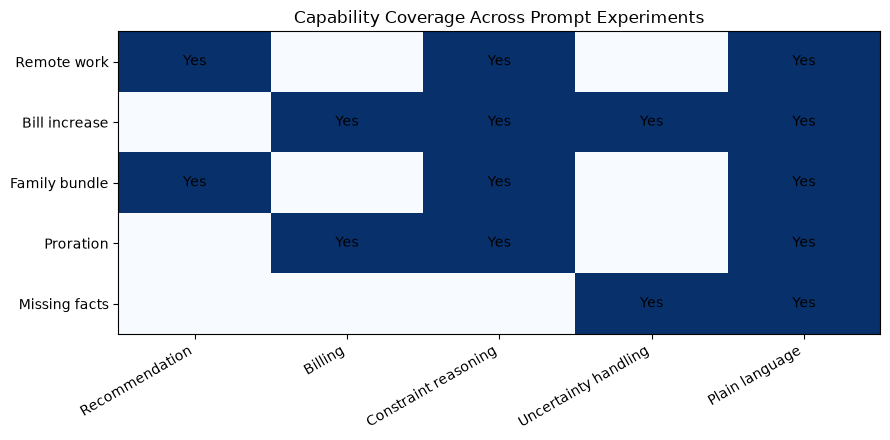

In [30]:
coverage = pd.DataFrame({
    "Experiment": ["Remote work", "Bill increase", "Family bundle", "Proration", "Missing facts"],
    "Recommendation": [1, 0, 1, 0, 0],
    "Billing": [0, 1, 0, 1, 0],
    "Constraint reasoning": [1, 1, 1, 1, 0],
    "Uncertainty handling": [0, 1, 0, 0, 1],
    "Plain language": [1, 1, 1, 1, 1],
}).set_index("Experiment")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.imshow(coverage.values, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(coverage.columns)), coverage.columns, rotation=30, ha="right")
ax.set_yticks(range(len(coverage.index)), coverage.index)
ax.set_title("Capability Coverage Across Prompt Experiments")
for i in range(coverage.shape[0]):
    for j in range(coverage.shape[1]):
        ax.text(j, i, "Yes" if coverage.iloc[i, j] else "", ha="center", va="center")
plt.tight_layout()
plt.show()


### Run the Prompting Experiments

The lightweight Qwen2.5-0.5B-Instruct model is loaded once. Each of the five scenarios is then run with zero-shot, one-shot, and chain-of-thought prompting, producing 15 responses for comparison.

In [31]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype="auto",
    device_map="auto"
)
model.eval()
print("Model loaded on:", model.device)


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Model loaded on: mps:0


In [32]:
PROMPT_STRATEGIES = ["Zero-shot", "One-shot", "Chain-of-thought"]

ONE_SHOT_USER = """Plans: Basic 100 costs $35 with 100 Mbps; Plus 300 costs $55 with 300 Mbps. A customer streams HD, works from home twice a week, and has a $60 budget. Recommend one plan using only these facts."""
ONE_SHOT_ASSISTANT = """1. Customer need
The customer needs streaming and occasional work-from-home service within $60.

2. Recommendation or explanation
Plus 300 is the stronger option.

3. Evidence
It costs $55, fits the budget, and provides 300 Mbps.

4. Tradeoff or uncertainty
It costs $20 more than Basic 100. No data allowance or equipment information was provided.

5. Next step
Confirm any unlisted plan terms before changing service."""

def build_messages(strategy, user_prompt):
    messages = [{"role": "system", "content": SYSTEM_PROMPT}]
    if strategy == "One-shot":
        messages.extend([
            {"role": "user", "content": ONE_SHOT_USER},
            {"role": "assistant", "content": ONE_SHOT_ASSISTANT},
        ])
    elif strategy == "Chain-of-thought":
        user_prompt += "\n\nFirst identify the stated constraints, then give a concise answer supported by the supplied evidence. Check the budget and note one tradeoff or uncertainty. Do not add unsupported details."
    messages.append({"role": "user", "content": user_prompt})
    return messages

def generate_response(model, tokenizer, user_prompt, strategy, max_new_tokens=150):
    messages = build_messages(strategy, user_prompt)
    text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(model.device)
    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id,
        )
    generated = output_ids[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(generated, skip_special_tokens=True).strip()

prompt_results = []
for strategy in PROMPT_STRATEGIES:
    for item in experiments:
        response = generate_response(model, tokenizer, item["prompt"], strategy)
        prompt_results.append({**item, "strategy": strategy, "response": response})
        print(f"\n--- {strategy} | Experiment {item['id']}: {item['name']} ---\n{response}\n")

prompt_results_df = pd.DataFrame(prompt_results)
prompt_results_df.to_csv(OUTPUT_DIR / "prompt_strategy_results.csv", index=False)
prompt_results_df[["id", "name", "strategy", "response"]]


--- Zero-shot | Experiment 1: Remote worker plan recommendation ---
Based on your requirements, I recommend the **Work 500** plan.

### Explanation:

- **Cost**: The Work 500 plan offers a lower monthly cost compared to the other options. It costs $70 per month, which is significantly cheaper than the Connect 200 at $45 per month and the Gig 1000 at $95 per month.
  
- **Features**: While both the Work 500 and Gig 1000 offer high-speed internet access (500 Mbps download and 50 Mbps upload), the Work 500 includes additional benefits such as unlimited data usage up to 1,000 Mbps, which can be beneficial if you


--- Zero-shot | Experiment 2: Confirmed promotional credit expiration ---
The increase in your bill from $80 to $100 could be due to several reasons such as an unexpected expense, a sale on a product you didn't purchase, or a change in your subscription plans. Since no other charges have altered, it might be worth checking if there was any additional spending during the month th

,id,name,strategy,response
0,1,Remote worker plan recommendation,Zero-shot,"Based on your requirements, I recommend the **..."
1,2,Confirmed promotional credit expiration,Zero-shot,The increase in your bill from $80 to $100 cou...
2,3,Family bundle comparison,Zero-shot,Recommendation: **Family Gig**\n\n**Tradeoff:*...
3,4,Prorated charge explanation,Zero-shot,The customer's upgrade has been prorated based...
4,5,Insufficient information,Zero-shot,Could you please provide more details about yo...
5,1,Remote worker plan recommendation,One-shot,1. Available plans: \n - Connect 200: $45/mo...
6,2,Confirmed promotional credit expiration,One-shot,The increase in the customer's bill from $80 t...
7,3,Family bundle comparison,One-shot,Recommend Family Gig at $105 with unlimited da...
8,4,Prorated charge explanation,One-shot,"Under prorated billing, the charges are based ..."
9,5,Insufficient information,One-shot,1. What's your current internet speed?\n2. How...


## Evaluation

Each observed response is scored from 1 (poor) to 5 (strong):

- **Groundedness:** Uses only supplied facts.
- **Relevance:** Addresses the customer need and constraints.
- **Clarity:** Communicates clearly.
- **Completeness:** Includes the requested elements.
- **Safety:** Avoids unsupported claims and handles uncertainty responsibly.

The scores below reflect the generated responses from this notebook, not expected performance.

In [33]:
score_columns = ["groundedness", "relevance", "clarity", "completeness", "safety"]

score_values = [
    # strategy, experiment id, groundedness, relevance, clarity, completeness, safety
    ("Zero-shot", 1, 2, 4, 3, 2, 2),
    ("Zero-shot", 2, 1, 2, 3, 2, 1),
    ("Zero-shot", 3, 1, 3, 2, 3, 1),
    ("Zero-shot", 4, 2, 3, 2, 2, 2),
    ("Zero-shot", 5, 5, 5, 5, 4, 5),
    ("One-shot", 1, 2, 3, 3, 2, 2),
    ("One-shot", 2, 1, 2, 3, 2, 1),
    ("One-shot", 3, 2, 4, 4, 3, 2),
    ("One-shot", 4, 1, 3, 2, 2, 1),
    ("One-shot", 5, 5, 5, 5, 4, 5),
    ("Chain-of-thought", 1, 2, 4, 3, 2, 2),
    ("Chain-of-thought", 2, 1, 2, 3, 2, 1),
    ("Chain-of-thought", 3, 2, 4, 4, 3, 2),
    ("Chain-of-thought", 4, 1, 2, 2, 1, 1),
    ("Chain-of-thought", 5, 5, 5, 5, 5, 5),
]

experiment_names = {item["id"]: item["name"] for item in experiments}
scores = pd.DataFrame(
    [
        {
            "strategy": strategy,
            "id": experiment_id,
            "name": experiment_names[experiment_id],
            **dict(zip(score_columns, values)),
        }
        for strategy, experiment_id, *values in score_values
    ]
)
scores["overall"] = scores[score_columns].mean(axis=1)
scores

,strategy,id,name,groundedness,relevance,clarity,completeness,safety,overall
0,Zero-shot,1,Remote worker plan recommendation,2,4,3,2,2,2.6
1,Zero-shot,2,Confirmed promotional credit expiration,1,2,3,2,1,1.8
2,Zero-shot,3,Family bundle comparison,1,3,2,3,1,2.0
3,Zero-shot,4,Prorated charge explanation,2,3,2,2,2,2.2
4,Zero-shot,5,Insufficient information,5,5,5,4,5,4.8
5,One-shot,1,Remote worker plan recommendation,2,3,3,2,2,2.4
6,One-shot,2,Confirmed promotional credit expiration,1,2,3,2,1,1.8
7,One-shot,3,Family bundle comparison,2,4,4,3,2,3.0
8,One-shot,4,Prorated charge explanation,1,3,2,2,1,1.8
9,One-shot,5,Insufficient information,5,5,5,4,5,4.8


,groundedness,relevance,clarity,completeness,safety
strategy,,,,,
Zero-shot,2.2,3.4,3.0,2.6,2.2
One-shot,2.2,3.4,3.4,2.6,2.2
Chain-of-thought,2.2,3.4,3.4,2.6,2.2


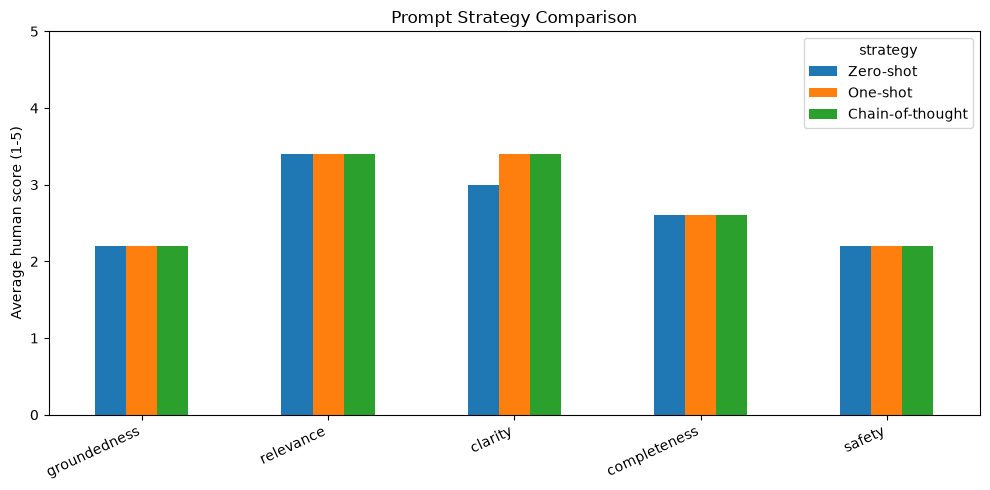

In [34]:
def validate_scores(df):
    numeric = df[score_columns].apply(pd.to_numeric, errors="coerce")
    invalid = numeric.isna() | ~(numeric.ge(1) & numeric.le(5))
    if invalid.any().any():
        raise ValueError("All rubric scores must be numeric values between 1 and 5.")
    return numeric

validate_scores(scores)
strategy_summary = scores.groupby("strategy", sort=False)[score_columns].mean().round(2)
display(strategy_summary)

ax = strategy_summary.T.plot(kind="bar", figsize=(10, 5))
ax.set_ylabel("Average human score (1-5)")
ax.set_title("Prompt Strategy Comparison")
ax.set_ylim(0, 5)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## Results and Comments

- One-shot and chain-of-thought prompting increased average clarity from **3.0** to **3.4**.
- Average groundedness (**2.2**), relevance (**3.4**), completeness (**2.6**), and safety (**2.2**) were unchanged across strategies.
- All strategies performed best when the correct response was to request missing information.
- The model frequently invented plan features or misunderstood billing facts. More elaborate prompts improved organization but did not reliably improve factual accuracy.

## Conclusion

The experiment did not identify a clearly superior prompting strategy. One-shot and chain-of-thought prompts produced slightly clearer responses, but they did not improve groundedness or safety over zero-shot prompting. For this lightweight model, adding prompt structure alone was not enough to prevent fabricated details or billing errors.

For a future milestone, the study could test stronger examples, retrieval of verified plan facts, or a larger model. Based on the current evidence, one-shot prompting is the most practical option because it matches the chain-of-thought scores with a simpler prompt.

## Responsible AI and Limitations

This prototype uses fictional plan and billing information and excludes personal or proprietary customer data. The generated responses are not suitable for real billing or service decisions without verification.

The main limitations are the small set of five scenarios, subjective human scoring, short response limit, and use of one lightweight model. The results describe this experiment only and should not be generalized to all models or telecom tasks.

## References

Brown, T. B., et al. (2020). Language models are few-shot learners. *Advances in Neural Information Processing Systems, 33*, 1877–1901. https://arxiv.org/abs/2005.14165

Qwen. (n.d.). *Qwen2.5-0.5B-Instruct* [Large language model]. Hugging Face. https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct

Wei, J., et al. (2022). Chain-of-thought prompting elicits reasoning in large language models. *Advances in Neural Information Processing Systems, 35*, 24824–24837. https://arxiv.org/abs/2201.11903